In [1]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt



import precision_recall as pr


# importlib.reload(plot_time_series)
import gc  # garbage collector
import glob  # i don't know if there is a better way to do this but this was the

# internet's suggestion for searching with an incomplete path name
import review_findings_functions as rff
import os



import importlib

Matplotlib is building the font cache; this may take a moment.


In [3]:
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [6]:

df_paths_2 = "predsarrays_offset_reduced_more/"

df_neg_base_path = "/lustre/lrspec/ZTF_data/efficiency_testing/full_image_implantations_neg/"
df_pos_base_path = "/lustre/lrspec/ZTF_data/efficiency_testing/full_image_implantations_pos/"

df_neg = pd.read_csv(f"{df_neg_base_path+df_paths_2}"+"df_matched")
df_pos =  pd.read_csv(f"{df_pos_base_path+df_paths_2}"+"df_matched")

In [7]:
df_pos = df_pos.drop(columns=['Unnamed: 0.1', 'Unnamed: 0'])

In [13]:
df_pos[df_pos['dist_to_implant']>50]

,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,Diff,brightness_ranking,quadrant,num_in_file_in_star,dup_indices,is_smaller_dup,dist_to_implant,row_from_implant,col_from_implant,A_from_implant,sig_from_implant
1,ztf_20220820237546_000798_zr_c16_x_0001.,1,pos,391.000000,2886.500000,2,2835.0,219.0,-61.500000,9,1,3.0,[],0.0,1101.426915,634.0,1820.0,1.15,3.0
11,ztf_20220820237546_000798_zr_c16_x_0001.,1,neg,282.560000,1169.120000,25,1103.0,856.0,-76.120000,21,1,2.0,[13 14],1.0,726.160071,634.0,1820.0,1.15,3.0
13,ztf_20220820237546_000798_zr_c16_x_0001.,1,neg,287.625000,1189.000000,8,1278.0,562.0,79.000000,4,1,4.0,[11],1.0,706.250055,634.0,1820.0,1.15,3.0
14,ztf_20220820237546_000798_zr_c16_x_0001.,1,neg,298.055556,1168.916667,36,1103.0,856.0,-75.916667,21,1,2.0,[11],0.0,719.185387,634.0,1820.0,1.15,3.0
15,ztf_20220820237546_000798_zr_c16_x_0001.,1,neg,387.500000,2885.500000,32,2835.0,219.0,-60.500000,9,1,3.0,[16],1.0,1101.195941,634.0,1820.0,1.15,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4550,ztf_20221017148750_000831_zi_c04_x_0023.,1,pos,2064.200000,3041.300000,10,3051.0,1121.0,-0.300000,1,1,1.0,[],0.0,691.226106,2739.0,2862.0,8.00,4.0
4552,ztf_20221017148750_000831_zi_c04_x_0023.,1,pos,2360.600000,2852.800000,5,2861.0,1404.0,-1.800000,3,1,5.0,[],0.0,368.400869,2739.0,2862.0,8.00,4.0
4571,ztf_20221017148750_000831_zi_c04_x_0023.,1,neg,2746.500000,2317.500000,12,2191.0,483.0,-136.500000,23,1,1.0,[],0.0,534.786406,2739.0,2862.0,8.00,4.0
4584,ztf_20221017148750_000831_zi_c04_x_0019.,1,pos,2467.000000,2852.000000,1,2861.0,1404.0,-1.000000,3,1,2.0,[],0.0,1112.976639,2383.0,1753.0,3.00,9.0


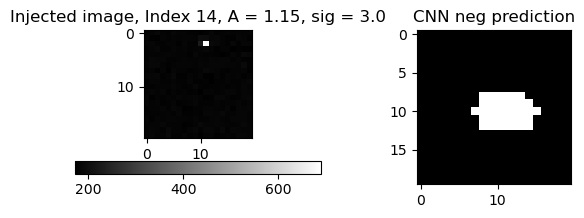

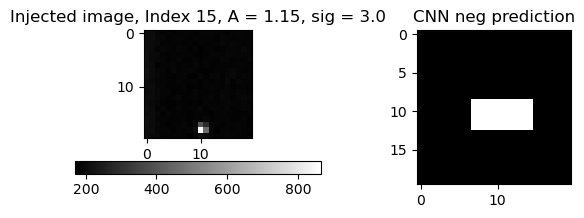

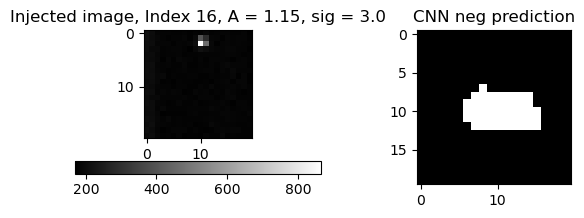

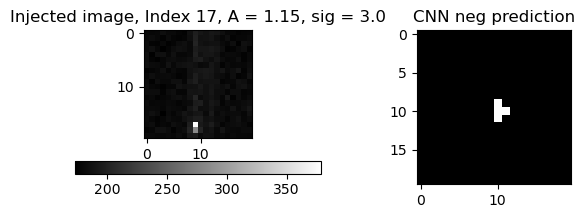

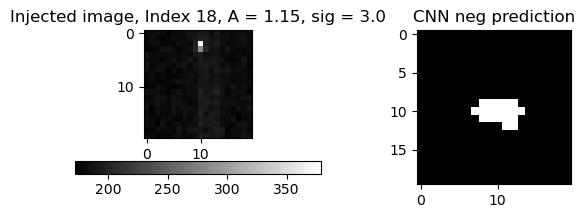

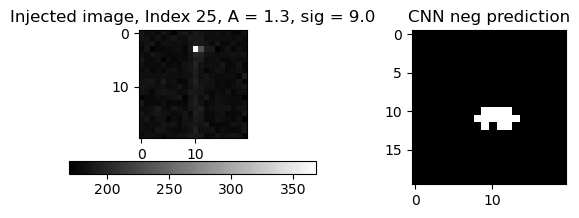

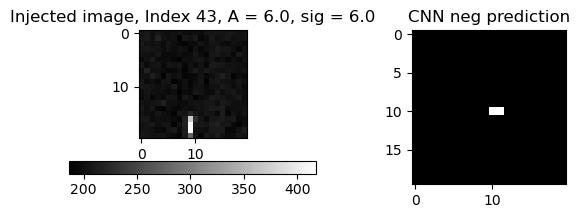

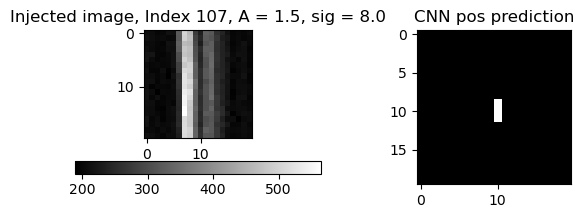

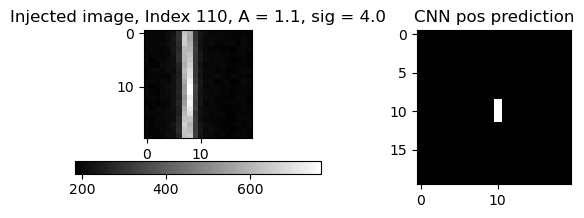

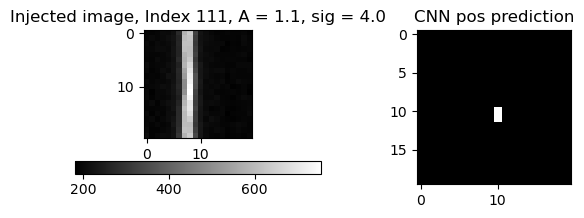

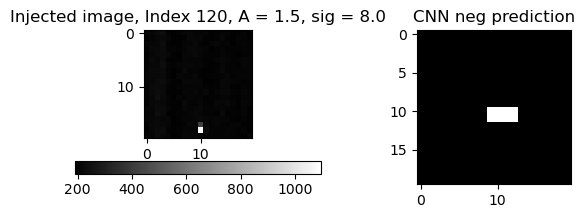

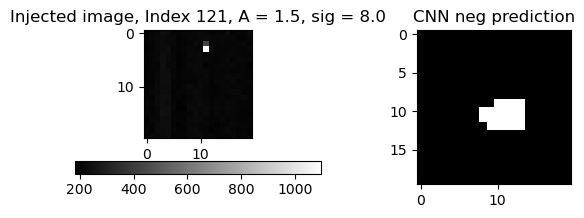

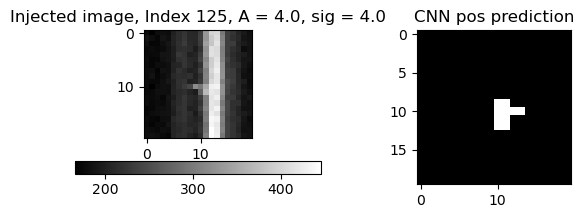

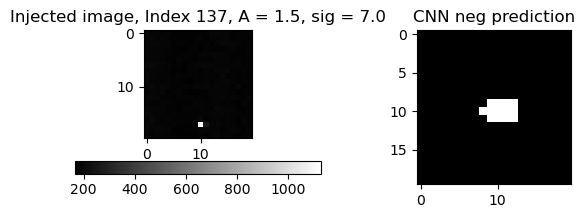

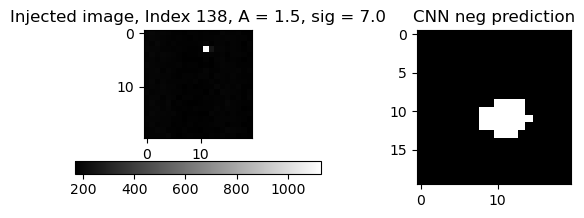

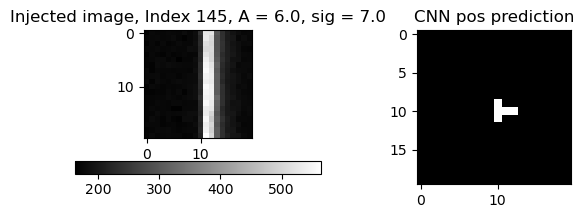

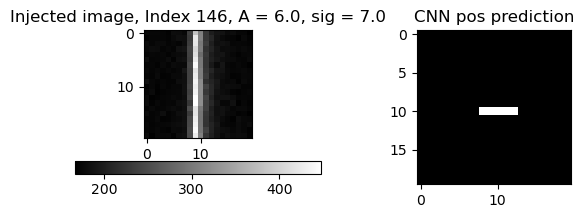

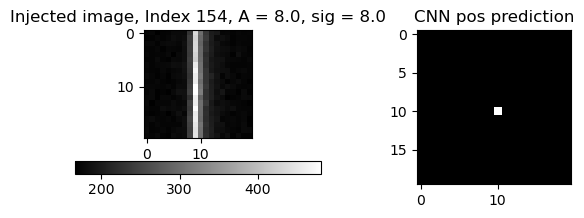

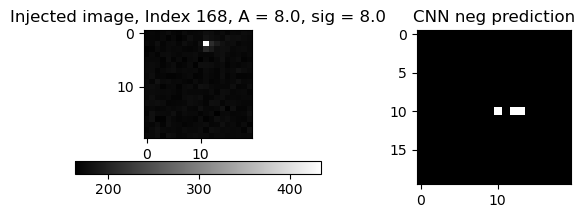

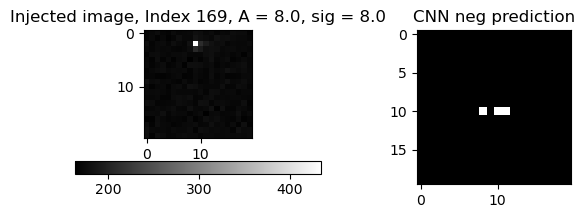

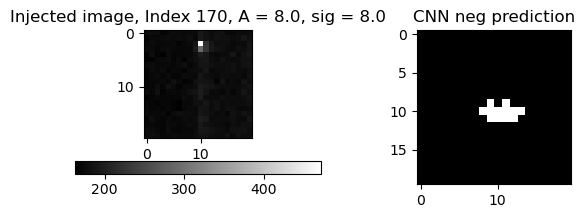

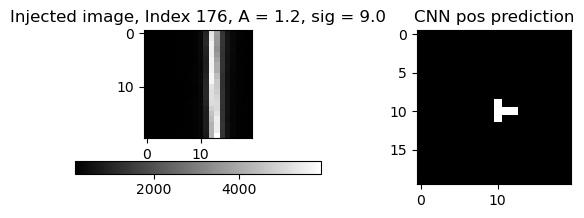

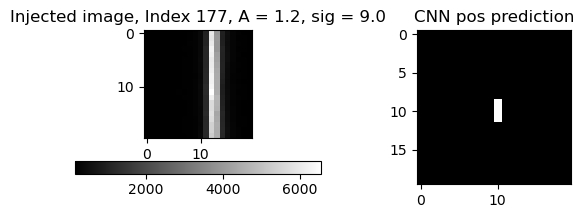

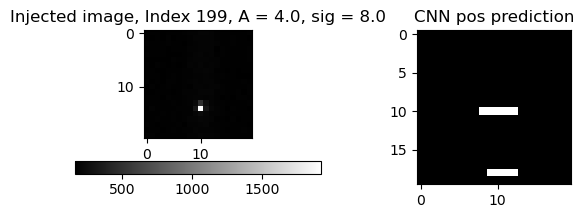

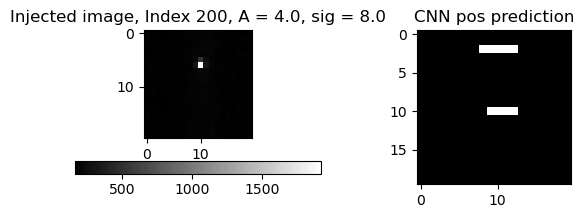

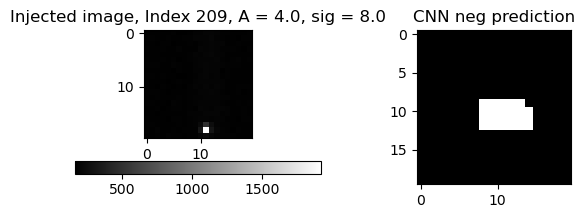

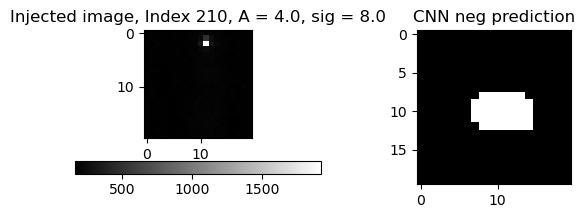

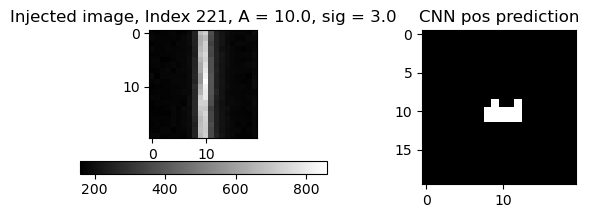

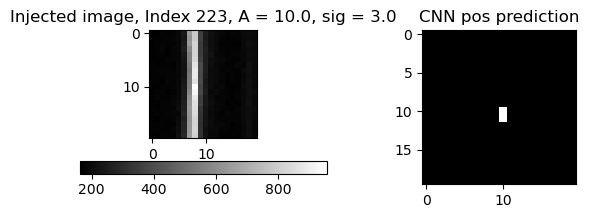

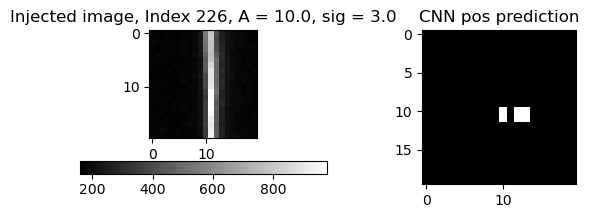

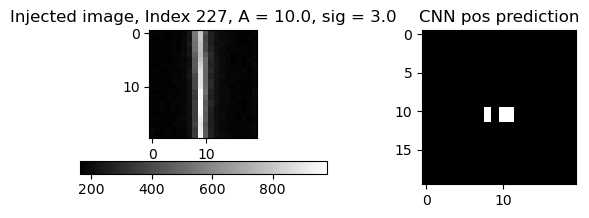

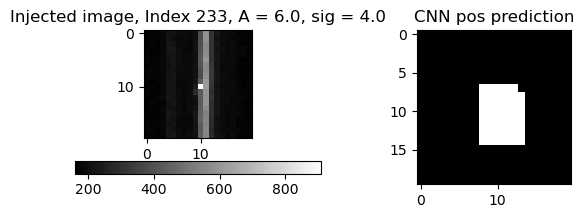

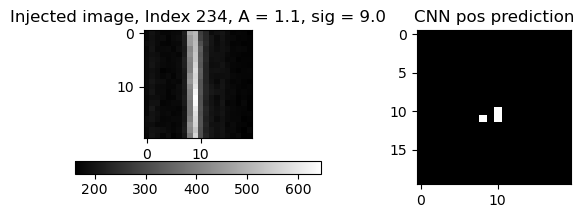

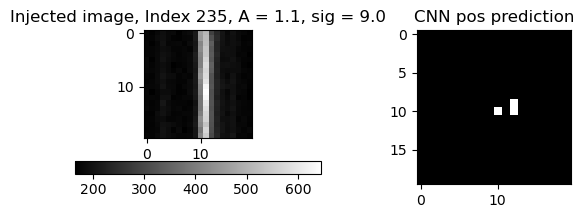

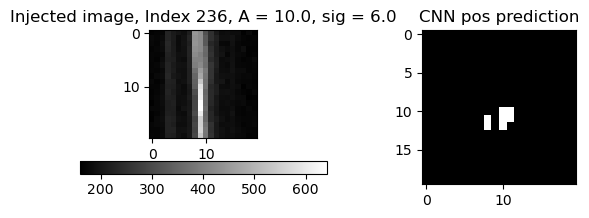

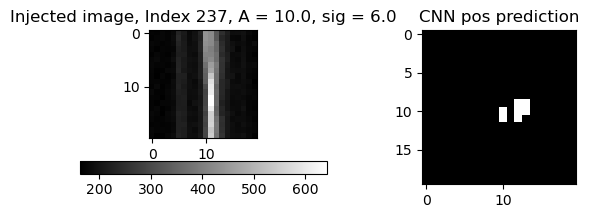

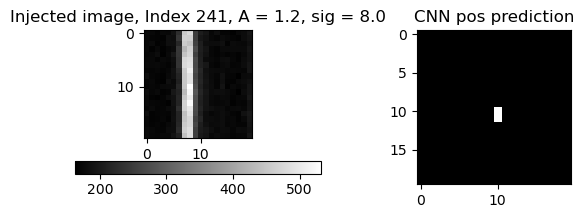

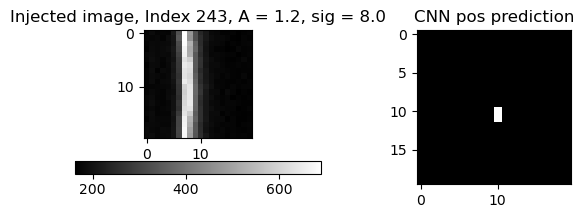

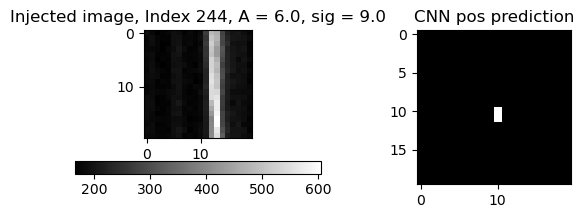

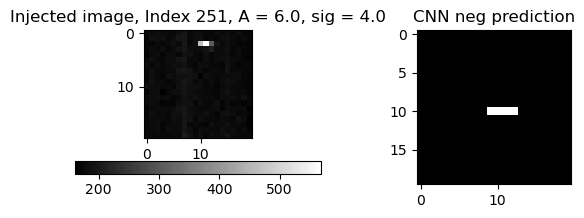

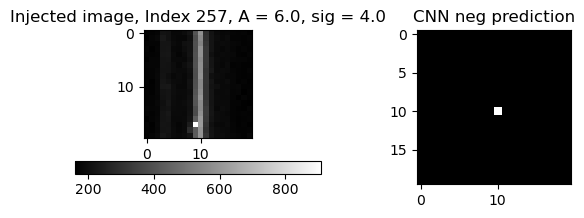

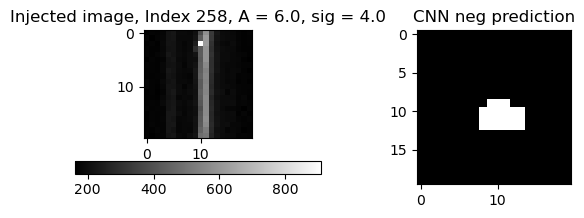

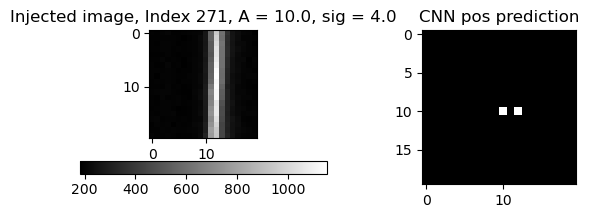

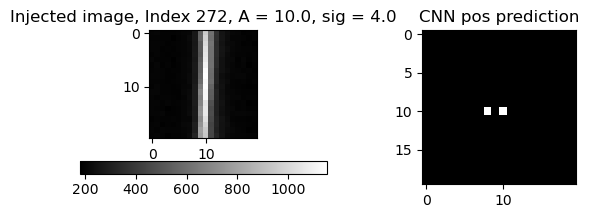

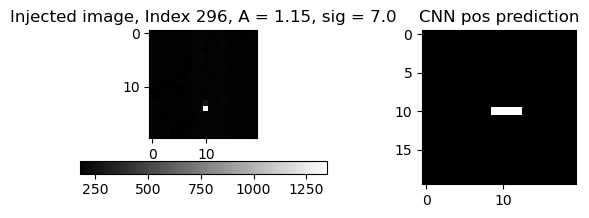

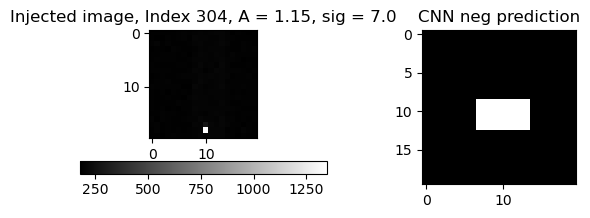

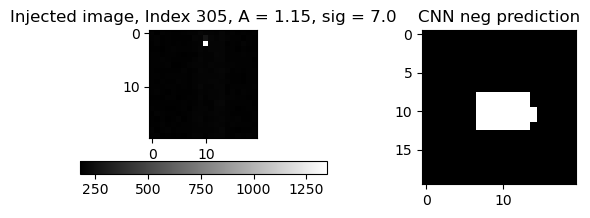

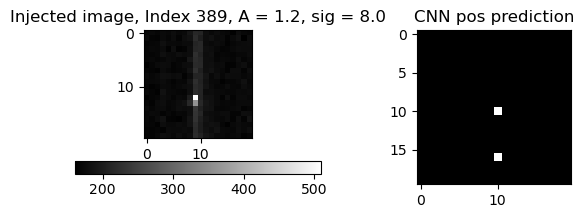

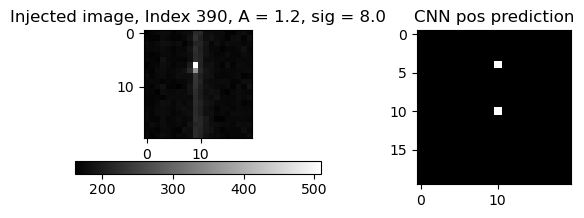

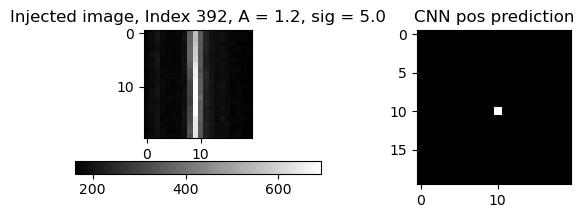

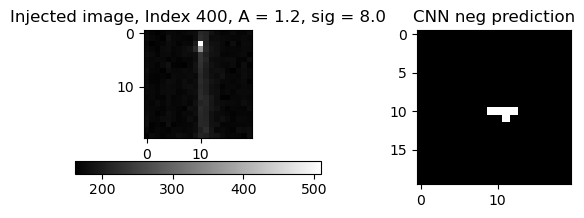

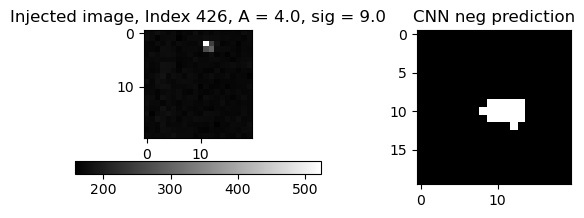

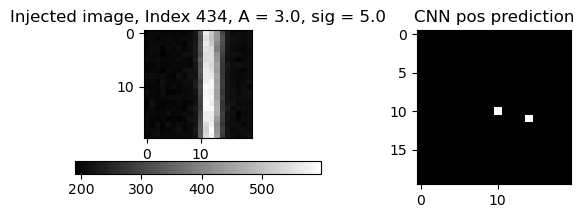

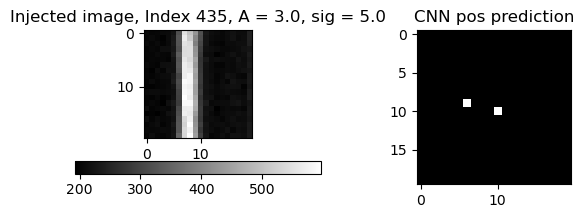

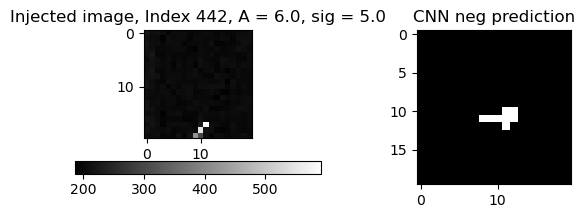

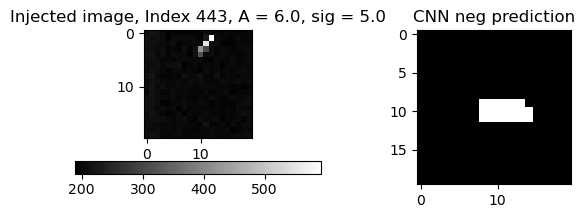

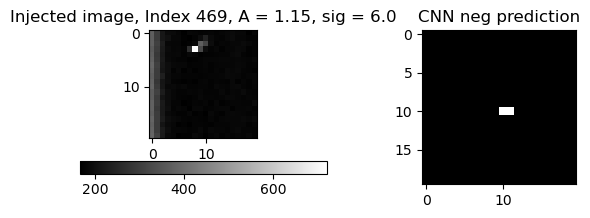

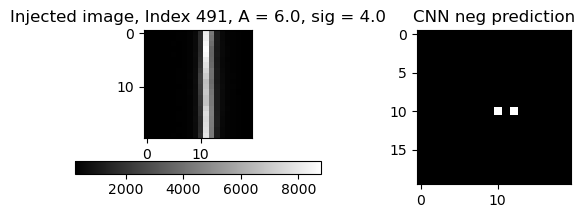

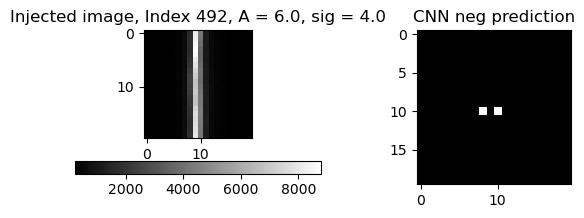

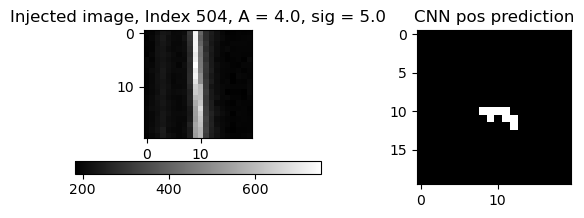

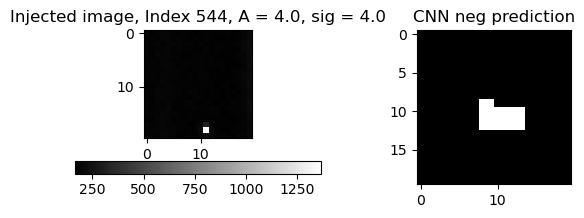

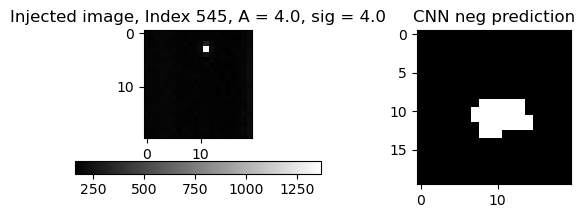

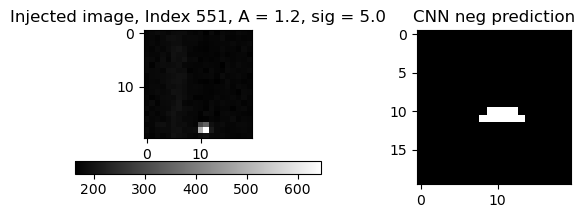

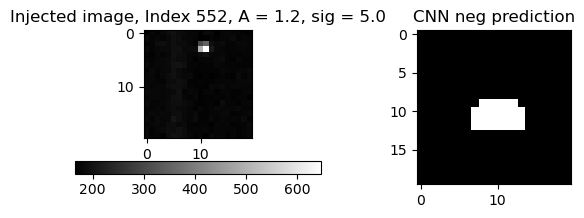

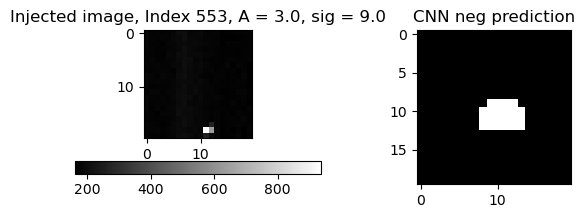

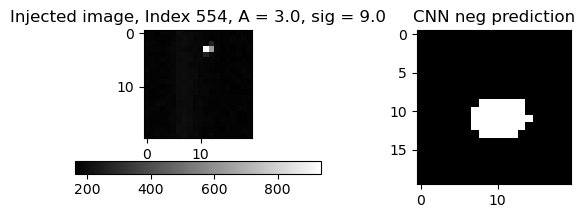

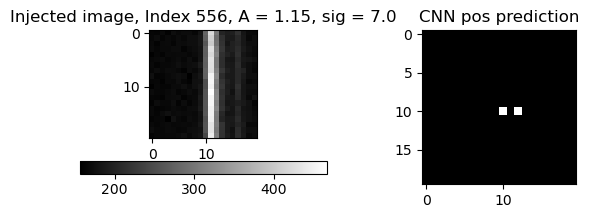

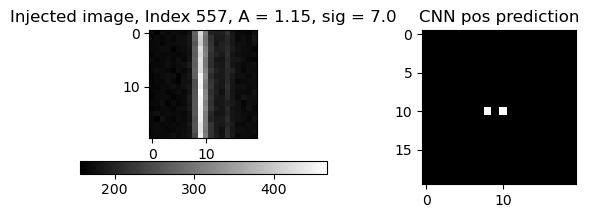

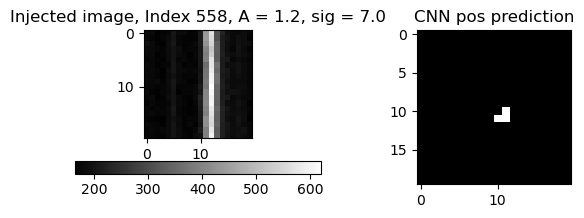

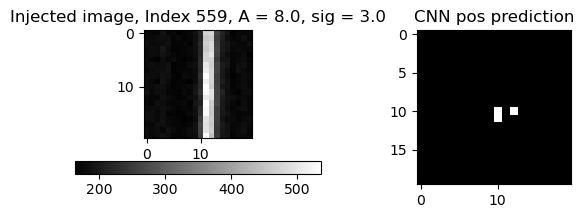

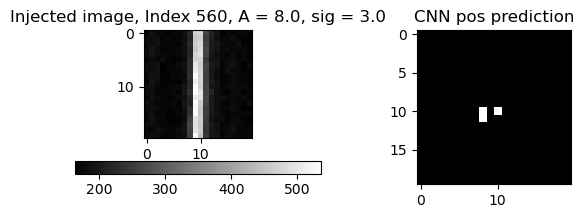

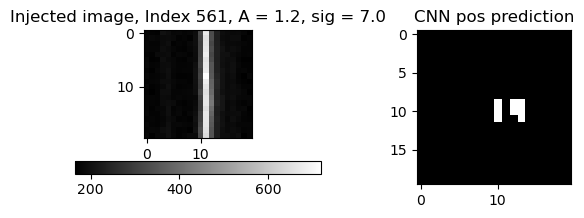

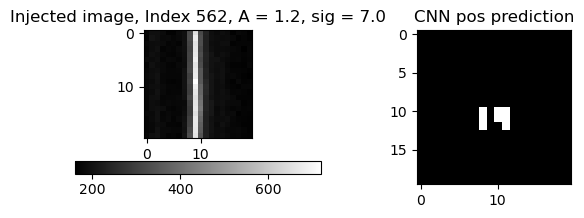

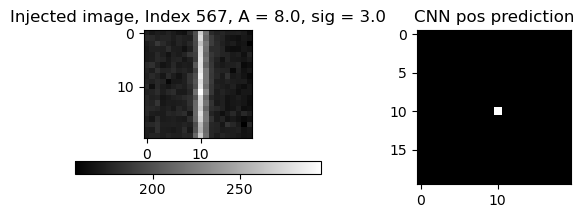

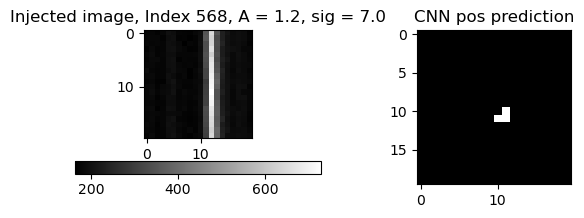

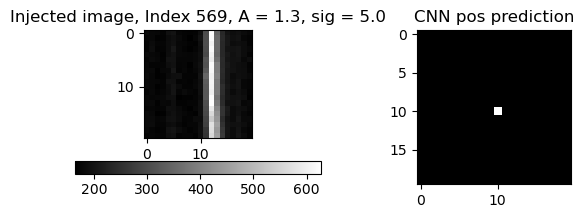

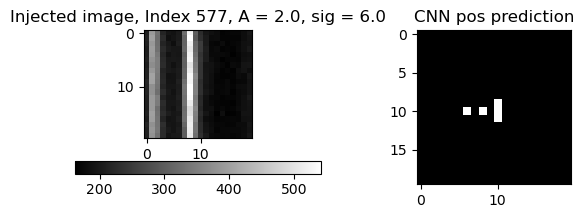

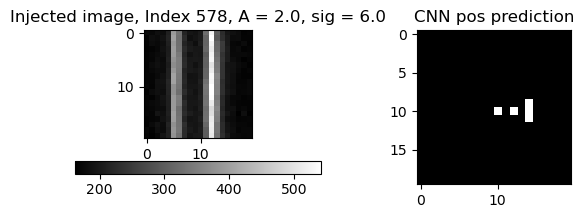

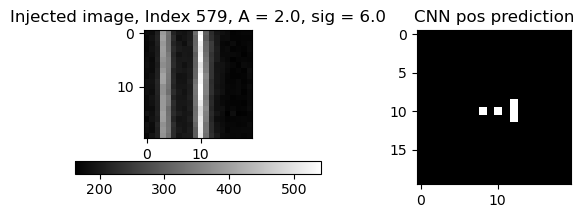

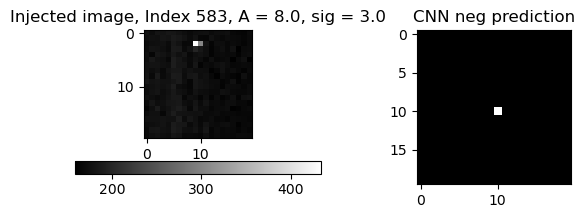

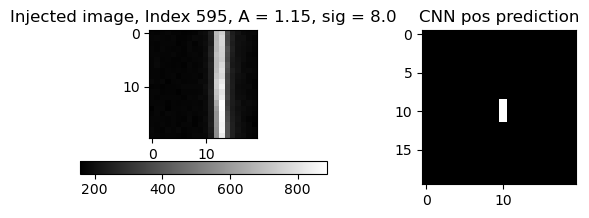

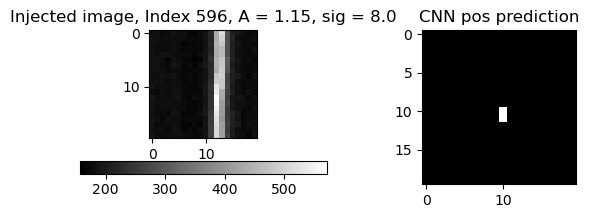

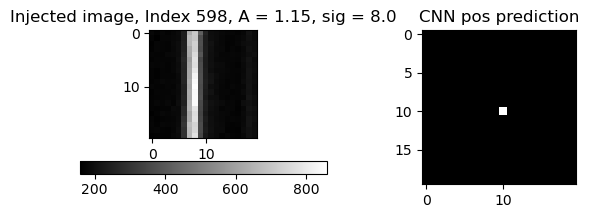

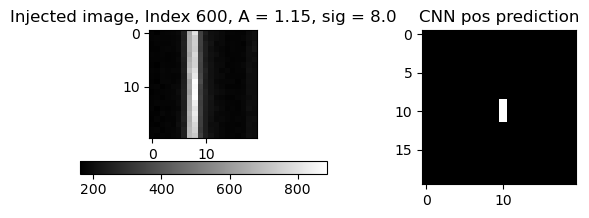

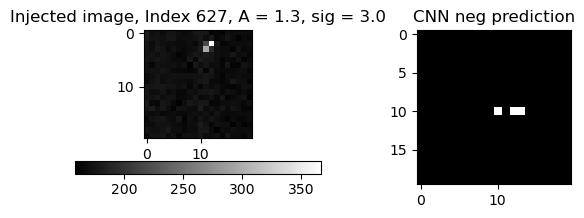

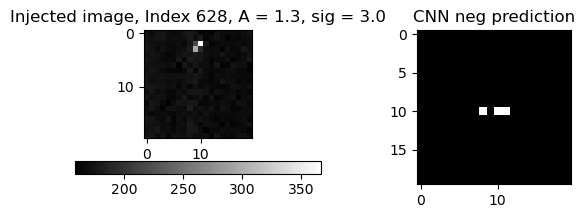

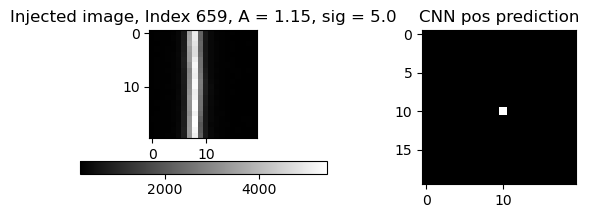

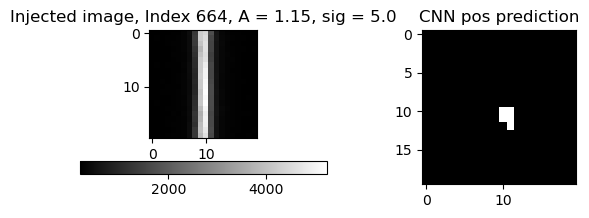

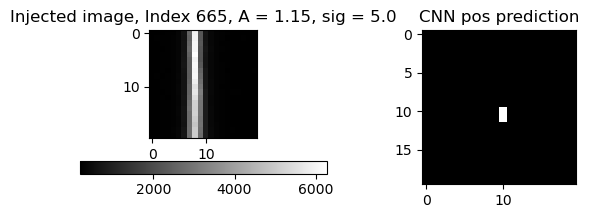

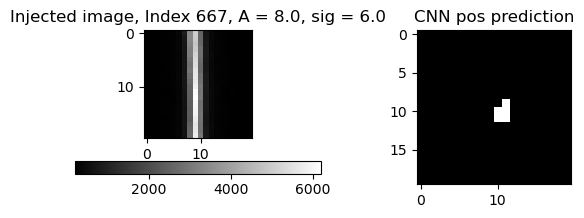

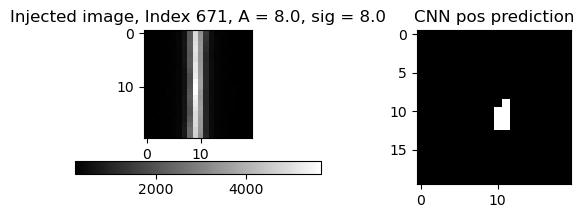

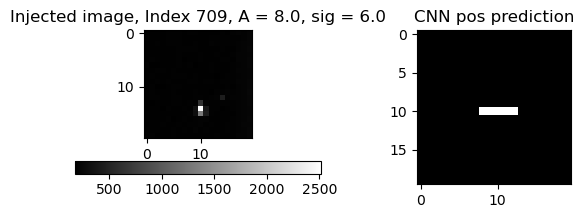

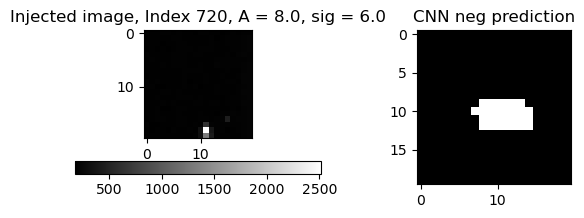

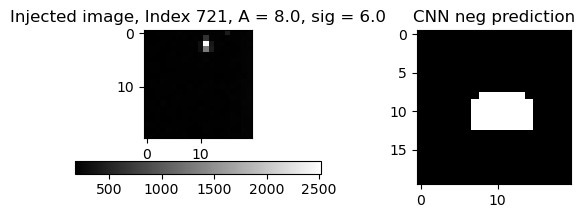

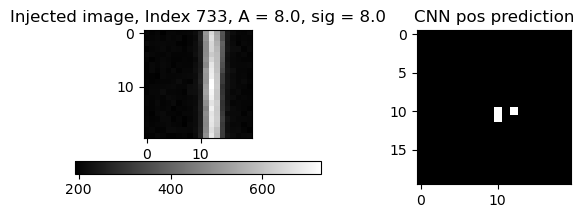

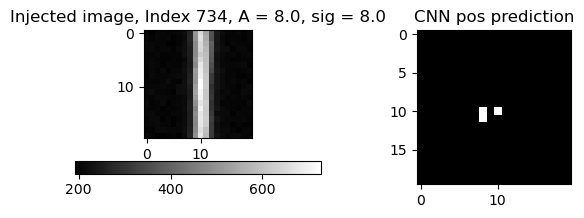

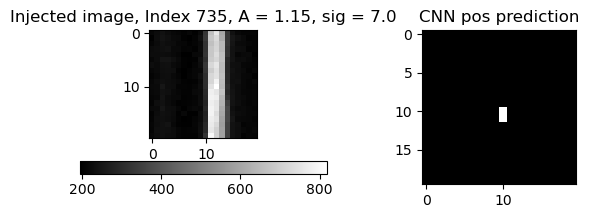

In [14]:
for index in df_pos[df_pos['dist_to_implant']>50].index[3:100]:
    rff.inspect_stamp_and_map(df_pos, index, posneg='pos',pdirec=df_paths_2)

In [16]:
def get_histtable(df):
    '''
    sort by the thing you want, it keeps the last (biggest)
    '''
    data = df.drop_duplicates(subset=["filename", "type","row_from_implant", "col_from_implant"], keep="last")["A_from_implant"]
    print(len(data))
    return data

def make_bar(df, label, binbounds, ax, alpha=.5):
    data = get_histtable(df)
    hist, bin_edges = np.histogram(data,binbounds)
    return ax.bar(range(len(hist)),hist,width=1,align='center',tick_label=
        ['{}'.format(bins[i]+.001) for i,j in enumerate(hist)], alpha=alpha, label=label)

base_path = "/lustre/lrspec/ZTF_data/efficiency_testing/"


both = pd.concat([df_neg[df_neg['type']=='neg'],df_pos[df_pos['type']=='pos']], ignore_index=True)

df_implants_pos = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/full_image_implantations_pos/df_implants_pos")
df_implants_neg = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/full_image_implantations_neg/df_implants_neg")


binbounds = list(np.unique(np.concatenate([df_implants_neg["A_from_implant"],
                                           [1],
                                           df_implants_pos["A_from_implant"],
                                           [np.unique(df_implants_pos["A_from_implant"])[-1]+.002]]))-.001)


In [ ]:
both = pd.concat([df_neg[df_neg['type']=='neg'],df_pos[df_pos['type']=='pos']], ignore_index=True)


In [18]:

df_paths_2 = "predsarrays_newrange/"

df_neg_base_path = "/lustre/lrspec/ZTF_data/efficiency_testing/full_image_implantations_neg/"
df_pos_base_path = "/lustre/lrspec/ZTF_data/efficiency_testing/full_image_implantations_pos/"

df_neg2 = pd.read_csv(f"{df_neg_base_path+df_paths_2}"+"df_matched")
df_pos2 =  pd.read_csv(f"{df_pos_base_path+df_paths_2}"+"df_matched")
both2 = pd.concat([df_neg2[df_neg2['type']=='neg'],df_pos2[df_pos2['type']=='pos']], ignore_index=True)


In [20]:
df_paths_2 = "predsarrays_dup_3/"

df_neg3 = pd.read_csv(f"{df_neg_base_path+df_paths_2}"+"df_matched")
df_pos3 =  pd.read_csv(f"{df_pos_base_path+df_paths_2}"+"df_matched")
both3 = pd.concat([df_neg3[df_neg3['type']=='neg'],df_pos3[df_pos3['type']=='pos']], ignore_index=True)


3469
3161
2720


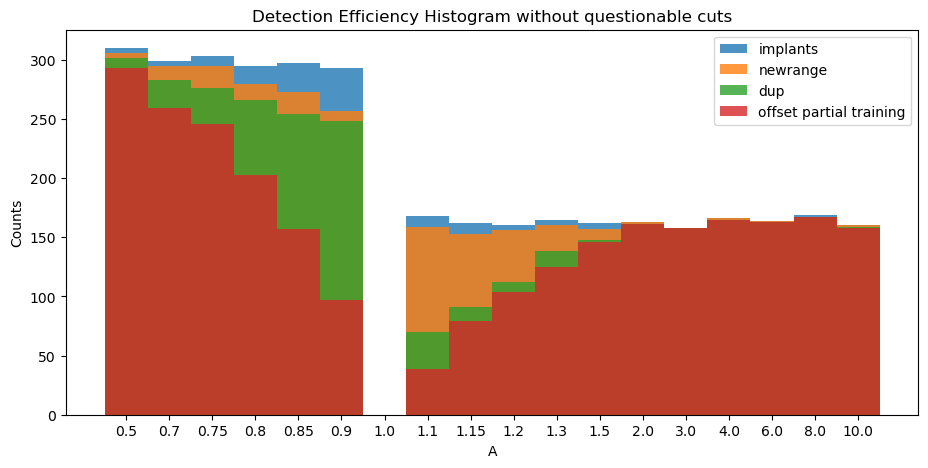

In [31]:
bins = binbounds
fig,ax = plt.subplots(figsize=(11,5))
alpha = .8

implants = np.concatenate([df_implants_neg["A_from_implant"],df_implants_pos["A_from_implant"]])
hist_implants, bin_edges = np.histogram(implants,bins) # make the histogram
ax.bar(range(len(hist_implants)),hist_implants,width=1,align='center',tick_label=
        ['{}'.format(bins[i]+.001) for i,j in enumerate(hist_implants)], alpha=alpha, label="implants")




make_bar(both2, "newrange", binbounds, ax, alpha=alpha)
make_bar(both3, "dup", binbounds, ax, alpha=alpha)
make_bar(both, "offset partial training", binbounds, ax, alpha=alpha)


# make_bar(noedges, "reduced edges", binbounds, ax, alpha=alpha)
# make_bar(matched[matched["Diff"]<10], "diff<10", binbounds, ax, alpha=alpha)
# make_bar(matched[matched["Diff"]<5], "diff<5", binbounds, ax, alpha=alpha)
# make_bar(snrs[snrs["snr_local"]>.5].sort_values("snr_local"), "snr>0.5", binbounds, ax, alpha=alpha)
# make_bar(snrs[snrs["snr_local"]>1].sort_values("snr_local"), "snr>1", binbounds, ax, alpha=alpha)
# make_bar(snrs[snrs["snr_local"]>3].sort_values("snr_local"), "snr>3", binbounds, ax, alpha=alpha)
# make_bar(snrs[snrs["detection_size"]>1], "detection size>1", binbounds, ax, alpha=alpha)
# make_bar(snrs[snrs["detection_size"]>3], "detection size>3", binbounds, ax, alpha=alpha)
# make_bar(snrs[snrs["detection_size"]>5], "detection size>4", binbounds, ax, alpha=alpha)


plt.title("Detection Efficiency Histogram without questionable cuts")
plt.ylabel("Counts")
plt.xlabel("A")
plt.legend()
plt.show()

